Average predicted probability: 0.0692


PermutationExplainer explainer: 1001it [05:17,  2.98it/s]                          


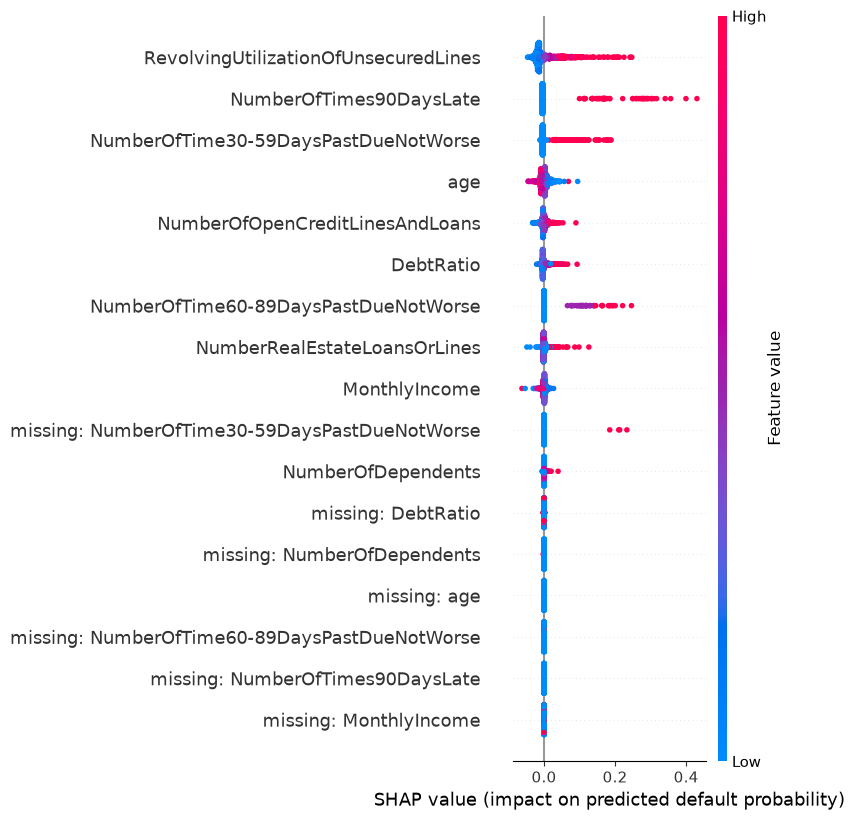

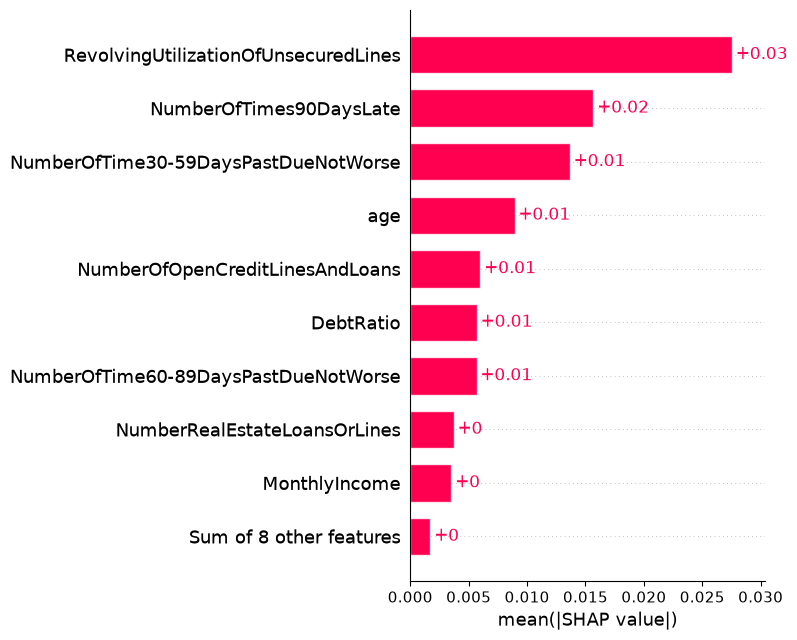

In [2]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from src.preprocessing import load_data, clean_data, split_data

data = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(data)

model = joblib.load("../models/loan_default_model.joblib")
prep = model.named_steps["prep"]
clf = model.named_steps["model"]

# Safety check: this must be the UNWEIGHTED (calibrated) model
assert clf.class_weight is None, "Old class-weighted model loaded. Rerun the retrain cells in 02_modeling."

# Transform the test data and give columns readable names
X_test_t = prep.transform(X_test)
names = [n.replace("num__", "").replace("missingindicator_", "missing: ")
         for n in prep.get_feature_names_out()]
X_sample = pd.DataFrame(X_test_t, columns=names).sample(1000, random_state=42)

# Sanity check: average predicted probability should be close to the real default rate (~6.7%)
print("Average predicted probability:", round(float(clf.predict_proba(X_sample.values)[:, 1].mean()), 4))

# Explain the default PROBABILITY, passing plain arrays to avoid feature-name warnings
def predict_default_proba(X):
    return clf.predict_proba(X)[:, 1]

background = shap.sample(X_sample, 100, random_state=42)
explainer = shap.Explainer(predict_default_proba, background.values, feature_names=names)
sv = explainer(X_sample.values)

# 1) Beeswarm: direction and size of each feature's effect
shap.summary_plot(sv, X_sample, show=False)
plt.xlabel("SHAP value (impact on predicted default probability)")
plt.tight_layout()
plt.savefig("../reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# 2) Bar chart: average importance of each feature
shap.plots.bar(sv, max_display=10, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()